## Imports

In [1]:
import sys
from pathlib import Path

project_base = Path.cwd().resolve().parents[1]
src_path = project_base / "src"
if src_path.exists():
    if str(src_path) not in sys.path:
        sys.path.insert(0, str(src_path))
else:
    print(f"[ERROR] Engine not found: {src_path}")
    sys.exit(1)

import time, pickle, os
import multiprocessing as mp
from typing import Tuple, Any, List
import numpy as np
from memory_profiler import profile,LineProfiler, show_results
#from cryptography.x509 import name
from PolynomialMatrixBuilder import PolynomialMatrixBuilder
from matplotlib import pyplot as plt
import VeraGridEngine.api as vge
from VeraGridEngine.Templates.Rms.genqec_phasor_rms_template import get_genqec_phasor
from VeraGridEngine.Simulations.Rms.numerical.back_euler_fx import BackEulerImplicitIntegration
from phasor_diagnostics import (
    check_pf_line_equations,
    check_equation_consistency,
    debug_exciter_equations,
    check_generator_current_residuals as compare_generator_bus_currents,
    check_shunt_pf_currents,
    print_buses_with_many_injections,
    print_bus_current_balance,
)
from scipy.optimize import linear_sum_assignment

from small_signal_tensygrid import op_extraction, solve_problem
import scienceplots
plt.style.use(['science', 'ieee', 'no-latex'])

C:\Users\Usuario\Desktop\git\VeraGrid\venv\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (7.0.1)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


## Options

In [2]:
grid_folder = project_base / "Grids_and_profiles" / "grids"
GRID = "IEEE 9 Bus.gridcal"
USE_CACHED_BUILDER = False
BUILDER_CACHE_FILE = f'trunk/tensygrid/precomputed_builds/{GRID}.pkl'

In [3]:
REPORT_TIME = False

FAST_MODE = False
LOGS = False
FULL_GRID_PATH = str(grid_folder / GRID)
FAST_GRID_PATH = FULL_GRID_PATH
PRINT_ALL_BUSES = LOGS
ENABLE_POST_COMPARE_PLOT = LOGS
RUN_DYNAMIC_STEP = False
RUN_CONSISTENCY_CHECK = False
RUN_PF_LINE_EQ_CHECK = False
RUN_EXCITER_DIAGNOSTICS = False
PF_LINE_FOCUS_INDEX = 0
DYNAMIC_SIM_TIME_FAST = 0.05
DYNAMIC_SIM_TIME_FULL = 0.20

EXEC_METRICS = {
    "n_vars": 0,
    "t_builder": 0.0,
    "t_solve": 0.0,
    "is_sparse": False,
    "stops":0
}

## Code

In [4]:
def define_problem_with_path(grid_path):
    """Creates the grid, runs the power flow, and returns the phasor problem."""
    print("\n[1] Creating phasor grid_path...")
    grid = vge.open_file(grid_path)

    # Build RMS models
    # Things we need to add: buses, branches, generators, transformers, loads, shunts

    ## BUSES:
    for bus in grid.buses:
        busec = vge.initialize_bus_phasor_rms(bus, vf=grid.var_factory)

    ## -GENERATORS
    for igen, gen in enumerate(grid.generators):
        genqec = vge.get_complete_generator_template_phasor(grid.var_factory, name=f"Gen{igen}").block


        genqec.connect([genqec.in_vars[0]], [gen.bus.rms_model.out_vars[0]])

        genqec.connect([genqec.in_vars[1]], [gen.bus.rms_model.out_vars[1]])
        vge.set_rms_model(device=gen, model=genqec, var_factory=grid.var_factory)

    ## -LINES:
    for line in grid.lines:
        lineec = vge.get_line_phasor_rms_template(grid.var_factory, name=line.name).block
        lineec.connect([lineec.in_vars[0]], [line.bus_from.rms_model.out_vars[0]])
        lineec.connect([lineec.in_vars[1]], [line.bus_from.rms_model.out_vars[1]])
        lineec.connect([lineec.in_vars[2]], [line.bus_to.rms_model.out_vars[0]])
        lineec.connect([lineec.in_vars[3]], [line.bus_to.rms_model.out_vars[1]])
        lineec = vge.to_implicit(lineec, grid.var_factory)
        vge.set_rms_model(device=line, model=lineec, var_factory=grid.var_factory)
    ## -LOADS:
    for load in grid.loads:
        loadec = vge.get_load_phasor_current_rms_template(grid.var_factory, name=load.name).block
        loadec.connect([loadec.in_vars[0]], [load.bus.rms_model.out_vars[0]])
        loadec.connect([loadec.in_vars[1]], [load.bus.rms_model.out_vars[1]])
        #loadec = vge.to_implicit(loadec, grid.var_factory)
        vge.set_rms_model(device=load, model=loadec, var_factory=grid.var_factory)
    ## -TRANSFORMERS 2w:
    for trafo in grid.transformers2w:
        trafoec = vge.initialize_trafo_rms(trafo, grid.var_factory, use_phasor_template=True).block
        trafoec.connect([trafoec.in_vars[0]], [trafo.bus_from.rms_model.out_vars[0]])
        trafoec.connect([trafoec.in_vars[1]], [trafo.bus_from.rms_model.out_vars[1]])
        trafoec.connect([trafoec.in_vars[2]], [trafo.bus_to.rms_model.out_vars[0]])
        trafoec.connect([trafoec.in_vars[3]], [trafo.bus_to.rms_model.out_vars[1]])
        trafoec = vge.to_implicit(trafoec, grid.var_factory)
        vge.set_rms_model(device=trafo, model=trafoec, var_factory=grid.var_factory)
    ## -SHUNTS (load like):
    for shunt in grid.shunts:
        shuntec = vge.get_shunt_template(grid.var_factory, name=shunt.name, phasor=True).block
        shuntec.connect([shuntec.in_vars[0]], [shunt.bus.rms_model.out_vars[0]])
        shuntec.connect([shuntec.in_vars[1]], [shunt.bus.rms_model.out_vars[1]])
        shuntec = vge.to_implicit(shuntec, grid.var_factory)
        vge.set_rms_model(device=shunt, model=shuntec, var_factory=grid.var_factory)

    # TRANSFORMERS 3W: Not present in existing grids and not supported
    print("  ✓ Grid with path loaded")

    # ===================================================================
    # POWER FLOW
    # ===================================================================

    print("\n[2] Running power flow...")
    #pf_options = vge.PowerFlowOptions(tolerance=1e-13)
    pf_options = vge.PowerFlowOptions(tolerance=1e-5)
    pf_results = vge.power_flow(grid, pf_options)

    if pf_results.converged:
        print(f"  ✓ Power flow converged")
        if PRINT_ALL_BUSES:
            for i, bus in enumerate(grid.buses):
                v = pf_results.voltage[i]
                print(f"    {bus.name}: Vm={abs(v):.4f} pu")
        else:
            vm = np.abs(pf_results.voltage)
            print(f"    Buses: {len(grid.buses)}, Vm[min/avg/max]=({vm.min():.4f}/{vm.mean():.4f}/{vm.max():.4f}) pu")
    else:
        print("  ✗ Power flow failed")
        return False

    if RUN_PF_LINE_EQ_CHECK:
        check_pf_line_equations(grid=grid, pf_results=pf_results)

    check_shunt_pf_currents(grid=grid, pf_results=pf_results)
    print("\n[2.7] Buses with multiple injection devices...")
    print_buses_with_many_injections(grid=grid)
    print_bus_current_balance(grid=grid, pf_results=pf_results)
    # ===================================================================
    # CREATE PHASOR PROBLEM
    # ===================================================================
    print("\n[3] Creating phasor problem...")

    rms_options = vge.RmsOptions(
        time_step=0.01,
        simulation_time=1.0,
        tolerance=1e-6,
        max_iter=20,
        verbose=True,
    )

    start_time= time.perf_counter()
    phasor_problem = vge.RmsProblemPhasor(grid=grid, options=rms_options, pf_results=pf_results)
    EXEC_METRICS["n_vars"] = phasor_problem.get_all_vars_number()
    end_time= time.perf_counter()
    print(f"\n[3.1.0] ⏰ Func phasor_problem took {end_time - start_time:.2f} seconds")
    print(f"  ✓ Phasor problem created with {phasor_problem.get_states_number()} states")
    if RUN_CONSISTENCY_CHECK:
        check_equation_consistency(phasor_problem)
    if RUN_EXCITER_DIAGNOSTICS:
        debug_exciter_equations(phasor_problem)
        compare_generator_bus_currents(problem=phasor_problem, pf_results=pf_results)
    print("\n[3.0] Exciter diagnostics...")
    #debug_exciter_equations(problem=phasor_problem)
    # ===================================================================
    # DYNAMIC VALIDATION
    # ===================================================================
    if RUN_DYNAMIC_STEP:
        print("\n[3.1.1] Running dynamic simulation...")
        dyn_t_end = DYNAMIC_SIM_TIME_FAST if FAST_MODE else DYNAMIC_SIM_TIME_FULL
        solver = BackEulerImplicitIntegration(
            problem=phasor_problem,
            t0=0,
            t_end=dyn_t_end,
            h=rms_options.time_step,
            max_iter=rms_options.max_iter,
            tolerance=rms_options.tolerance,
        )
        t_dyn, y_dyn, well_initialized, converged = solver.simulate()
        print(
            f"  ✓ Dynamic simulation finished: steps={len(t_dyn)}, "
            f"well_initialized={well_initialized}, converged={converged}, "
            f"final|x|={np.linalg.norm(y_dyn[-1, :]):.4e}"
        )
    return phasor_problem

In [5]:
# --- START CHRONO ---
start_time = time.perf_counter()

grid_path = FAST_GRID_PATH if FAST_MODE else FULL_GRID_PATH
print(f"[FAST_MODE={FAST_MODE}] Using grid: {grid_path}")

problem = None
calculated_evs = []

# 1. Check whether the builder cache exists BEFORE creating the problem
if USE_CACHED_BUILDER and os.path.exists(BUILDER_CACHE_FILE):
    print(f"\n[⏩] File '{BUILDER_CACHE_FILE}' found.")
    print("[⏩] Skipping Phasor Problem creation...")
    # Keep problem as None. solve_problem will load the .pkl internally.
    res = solve_problem(problem=problem)
    calculated_evs = res[0]
else:
    # 2. If there is no cache, run the normal heavy simulation
    problem = define_problem_with_path(grid_path)
    if problem:
        # Pass the newly created problem so it can be linearized and cached
        res, pf_map = solve_problem(problem=problem)
        calculated_evs = res[0]

# --- END CHRONO ---
end_time = time.perf_counter()
total_duration = end_time - start_time

print(f"\n========================================")
print(f"EXECUTION TIME: {total_duration:.4f} seconds")
print(f"========================================")

[FAST_MODE=False] Using grid: C:\Users\Usuario\Desktop\git\VeraGrid\Grids_and_profiles\grids\IEEE 9 Bus.gridcal

[1] Creating phasor grid_path...
  ✓ Grid with path loaded

[2] Running power flow...
  ✓ Power flow converged
    Buses: 9, Vm[min/avg/max]=(0.9956/1.0220/1.0400) pu

[2.7] Buses with multiple injection devices...
  No buses with >= 3 injection devices found.

[2.8] Bus current balance report...
  buses over tol=1.0e-08: 8
  bus 7        |err|=4.619940e-07 Br=(3.536e-07,-2.974e-07) G=(0.000e+00,0.000e+00) Bt=(0.000e+00,0.000e+00) L=(0.000e+00,0.000e+00) Sh=(0.000e+00,0.000e+00) Sl=(0.000e+00,0.000e+00) R=(3.536e-07,-2.974e-07)
  bus 8        |err|=2.927901e-07 Br=(-1.218e+00,5.883e-01) G=(0.000e+00,0.000e+00) Bt=(0.000e+00,0.000e+00) L=(-1.218e+00,5.883e-01) Sh=(0.000e+00,0.000e+00) Sl=(0.000e+00,0.000e+00) R=(-1.091e-07,-2.717e-07)
  bus 6        |err|=1.981409e-07 Br=(-9.887e-01,3.320e-01) G=(0.000e+00,0.000e+00) Bt=(0.000e+00,0.000e+00) L=(-9.887e-01,3.320e-01) Sh=(0.000

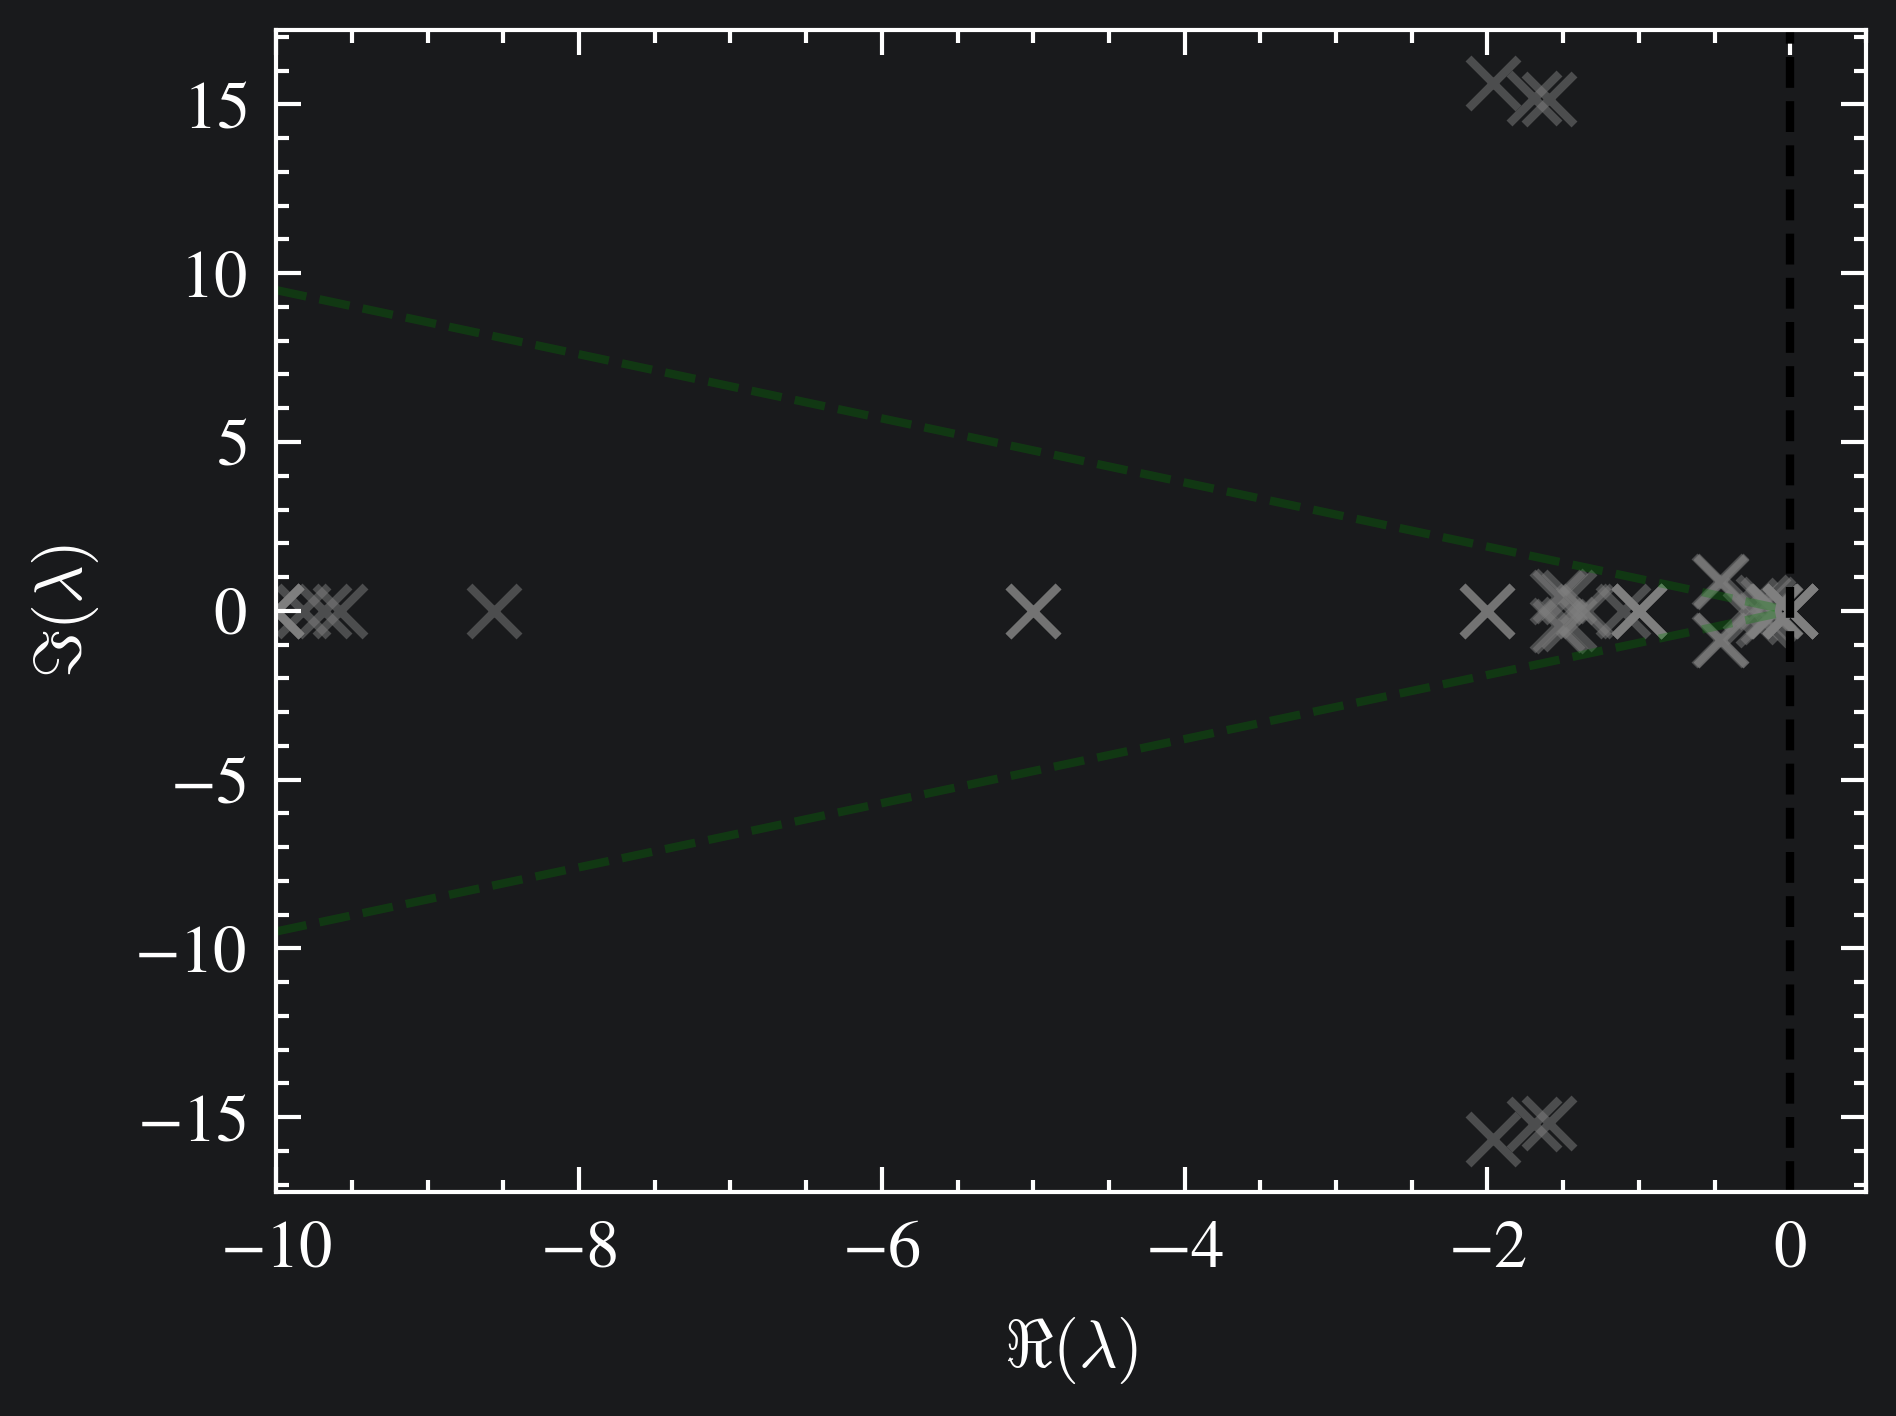

In [24]:
plt.scatter(np.real(calculated_evs), np.imag(calculated_evs),
                color='gray', marker='x', alpha=0.5, label="Pablo's computation")
xs = np.arange(-10, 1, 1)
ys = 0.95*xs
plt.plot(xs, ys, color='green', alpha=0.3, linestyle='dashed')
plt.plot(xs, -ys, color='green', alpha=0.3, linestyle='dashed')

plt.xlabel("$\\Re({\\lambda})$")
plt.ylabel("$\\Im({\\lambda})$")
plt.xlim(-10,0.5)
plt.axvline(0, linestyle='--', color='k')
plt.tight_layout()
plt.show()

In [25]:
for ev, participations in pf_map.items():
    if -1 < np.real(ev) < 0.0:
        print(f"\n--- Autovalor: {ev:.2f} ---")
        for var_name, pf in participations:
            if not str(var_name).startswith("u_"):
                print(f"  -> Variable {var_name}: {pf * 100:.2f}%")


--- Autovalor: -0.46+0.87j ---
  -> Variable PsidGen2: 2.63%
  -> Variable V_qag_aux_2: 2.31%
  -> Variable V_qagGen2: 2.03%

--- Autovalor: -0.46-0.87j ---
  -> Variable PsidGen2: 2.63%
  -> Variable V_qag_aux_2: 2.31%
  -> Variable V_qagGen2: 2.03%

--- Autovalor: -0.15+0.20j ---
  -> Variable V_qagGen2: 20.31%
  -> Variable Ed_primeGen2: 5.96%
  -> Variable PsidGen2: 4.33%
  -> Variable In_aux_2: 3.30%
  -> Variable Eq1Gen2: 2.62%
  -> Variable V_qag_aux_2: 2.46%

--- Autovalor: -0.15-0.20j ---
  -> Variable V_qagGen2: 20.31%
  -> Variable Ed_primeGen2: 5.96%
  -> Variable PsidGen2: 4.33%
  -> Variable In_aux_2: 3.30%
  -> Variable Eq1Gen2: 2.62%
  -> Variable V_qag_aux_2: 2.46%

--- Autovalor: -0.46+0.87j ---
  -> Variable PsidGen1: 2.67%
  -> Variable V_qag_aux_1: 2.46%

--- Autovalor: -0.46-0.87j ---
  -> Variable PsidGen1: 2.67%
  -> Variable V_qag_aux_1: 2.46%

--- Autovalor: -0.47+0.87j ---
  -> Variable PsidGen0: 2.22%
  -> Variable V_qag_aux: 2.14%

--- Autovalor: -0.47-0.8